In [13]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [14]:
# how pendulum env works:
# Pendulum starts at a random angle, its goal is to swing up and stay balanced upright

# state s: theta (angle, 0 = upright, in [-pi, pi]) and theta_dot (angular velocity, in [-8, 8])
# but the env gives observation as [cos(theta), sin(theta), theta_dot]

# action a: torque in [-2, 2] (continuous action space)

# reward r: -(theta^2 + 0.1 * theta_dot^2 + 0.001 * torque^2), so best reward is 0 (upright, still (no angular velocity), no torque)

# no termination state, episode is truncated after 200 steps

# NOTE: no transition matrix env.P like frozen lake, as well as states and actions are continuous unlike frozen lake

env = gym.make("Pendulum-v1", render_mode="human")
observation, info = env.reset()

episode_over = False
while not episode_over:
    action = env.action_space.sample()  # random torque
    observation, reward, terminated, truncated, info = env.step(action)

    episode_over = terminated or truncated

env.close()

In [15]:
# value iteration

# Discretization of state space and action space
# we can change this number to figure out which size is good enough
num_theta_bins = 151
num_theta_dot_bins = 151
num_action_bins = 5

# arrays for these discrete states and actions
theta_bins = np.linspace(-np.pi, np.pi, num_theta_bins, dtype=np.float32)
theta_dot_bins = np.linspace(-8, 8, num_theta_dot_bins, dtype=np.float32)
action_bins = np.linspace(-2.0, 2.0, num_action_bins, dtype=np.float32)

# hyperparameters
gamma = 0.995
# to check the convergence, it's a threshold value
epsilon = 1e-4 

# value function for each state
V = np.zeros((num_theta_bins, num_theta_dot_bins), dtype=np.float32)
Policy = np.ones((num_theta_bins, num_theta_dot_bins), dtype= int)

# wrap any angle into the range [-pi, pi): -pi is included, pi is not
def theta_normalize(x):
    return ((x + np.pi) % (2 * np.pi)) - np.pi

# Pendulum has no transition matrix env.P like frozen lake, so we cannot ask the env
# "what is the next state?" for any state we want, we compute it ourselves
# using the same equations as the Pendulum-v1 source code
def pendulum_step(theta, theta_dot, action):
    # parameters
    g = 10.0  # gravitational constant
    l = 1.0   # length of pendulum
    m = 1.0   # mass of pendulum
    dt = 0.05 # time step

    # let's clip the input action for safety!
    action = np.clip(action, -2.0, 2.0)

    # approximation the simulation/env uses
    new_theta_dot = theta_dot + ((3*g)/(2*l) * np.sin(theta) + 3.0 * action/(m * l**2)) * dt
    new_theta_dot = np.clip(new_theta_dot, -8.0, 8.0)

    new_theta = theta + new_theta_dot * dt
    new_theta = theta_normalize(new_theta)

    return new_theta, new_theta_dot

# map a continuous value to the index of the nearest grid point in bins
def to_index(x, bins):
    step = bins[1] - bins[0]
    return np.clip(np.rint((x - bins[0]) / step).astype(int), 0, len(bins) - 1)

# precompute once, transitions never change: same (state, action) always gives the same next state
# NOTE: This is only possible in sim real world changes all the time ("no man ever steps in the same river twice, for it's not the same river and he's not the same man" - Heraclitus)
#       Also as the number of bin increase this will get harder and harder to do!
# shapes are (num_theta_bins, num_theta_dot_bins, num_action_bins) = every state x every action
theta_grid, theta_dot_grid, action_grid = np.meshgrid(theta_bins, theta_dot_bins, action_bins, indexing='ij')

# next state using pendulum dynamics (works on whole arrays at once)
next_theta, next_theta_dot = pendulum_step(theta_grid, theta_dot_grid, action_grid)

# get the discrete indices for the next state
next_theta_idx = to_index(next_theta, theta_bins)
next_theta_dot_idx = to_index(next_theta_dot, theta_dot_bins)

# can change the cost function to optimize the behavior of the learned policy
# cost = theta_normalize(theta_grid) ** 2 + 0.1 * theta_dot_grid ** 2 + 0.1 * action_grid ** 2
cost = theta_grid**2
R = - cost

print("starting a value iteration...")
num_iterations = 0

while True:
    num_iterations += 1

    # Bellman optimality equation for all states and actions at once
    Q = R + gamma * V[next_theta_idx, next_theta_dot_idx]
    V_new = Q.max(axis=-1)

    # to track convergence
    delta = np.abs(V_new - V).max()

    # after iterating over all states, update the main value function
    V = V_new
    print(f"Iteration {num_iterations:04d}, Max Delta: {delta:.6f}")

    # check for convergence
    if delta < epsilon:
        break

# best action for each state
Policy = Q.argmax(axis=-1)

print(f"\nValue Iteration converged in {num_iterations} iterations.")

starting a value iteration...
Iteration 0001, Max Delta: 9.869605
Iteration 0002, Max Delta: 9.820258
Iteration 0003, Max Delta: 9.771156
Iteration 0004, Max Delta: 9.722301
Iteration 0005, Max Delta: 9.673691
Iteration 0006, Max Delta: 9.625322
Iteration 0007, Max Delta: 9.577196
Iteration 0008, Max Delta: 9.529310
Iteration 0009, Max Delta: 9.481665
Iteration 0010, Max Delta: 9.434256
Iteration 0011, Max Delta: 9.387081
Iteration 0012, Max Delta: 9.340145
Iteration 0013, Max Delta: 9.047283
Iteration 0014, Max Delta: 9.002050
Iteration 0015, Max Delta: 8.957041
Iteration 0016, Max Delta: 8.912252
Iteration 0017, Max Delta: 8.867693
Iteration 0018, Max Delta: 8.823341
Iteration 0019, Max Delta: 8.779224
Iteration 0020, Max Delta: 8.735329
Iteration 0021, Max Delta: 8.691650
Iteration 0022, Max Delta: 8.648193
Iteration 0023, Max Delta: 8.604950
Iteration 0024, Max Delta: 8.561928
Iteration 0025, Max Delta: 8.519119
Iteration 0026, Max Delta: 8.476524
Iteration 0027, Max Delta: 8.43414

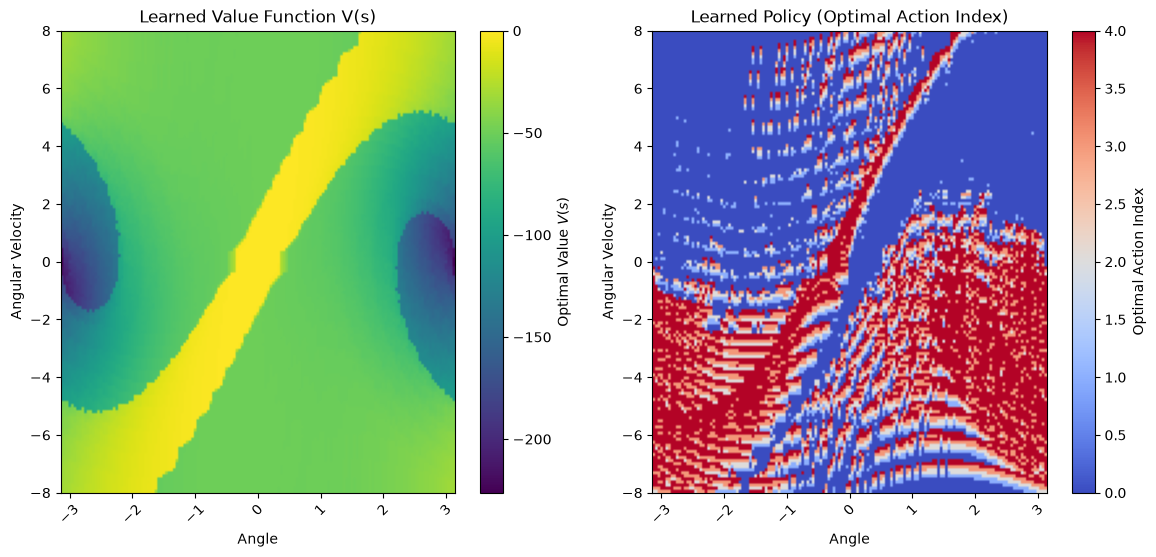

In [16]:
# plotting the value function and policy
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
plt.imshow(V.T, cmap='viridis',   # V.T because V(num_theta_bins, num_theta_dot_bins) goes to (y , x)
           extent=[theta_bins.min(), theta_bins.max(), theta_dot_bins.min(), theta_dot_bins.max()],
           aspect='auto')
plt.colorbar(label='Optimal Value $V(s)$')
plt.xlabel('Angle')
plt.ylabel('Angular Velocity') 
plt.title('Learned Value Function V(s)')
plt.xticks(rotation=45) # x axis label rotation

plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
plt.imshow(Policy.T, cmap='coolwarm',
           extent=[theta_bins.min(), theta_bins.max(), theta_dot_bins.min(), theta_dot_bins.max()],
           aspect='auto')
plt.colorbar(label='Optimal Action Index')
plt.xlabel('Angle')
plt.ylabel('Angular Velocity')
plt.title('Learned Policy (Optimal Action Index)')
plt.xticks(rotation=45)

plt.show()

To learn more about pendulum dynamics, watch
[Underactuated Robotics, Lecture 3](https://www.youtube.com/live/GPvw92IKO44?t=4250).

In [17]:
# Save the learned policy and value function
policy_filename = 'pendulum_value_iteration_policy.pkl'
with open(policy_filename, 'wb') as f:
    pickle.dump({'V': V, 'Policy': Policy}, f)
    
print(f"Policy and Value function saved to {policy_filename}")


Policy and Value function saved to pendulum_value_iteration_policy.pkl


In [18]:
import os
# open the saved policy
policy_filename = 'pendulum_value_iteration_policy.pkl'

V = None
Policy = None

if os.path.exists(policy_filename):
    with open(policy_filename, 'rb') as f:
        loaded_data = pickle.load(f)
        V = loaded_data['V']
        Policy = loaded_data['Policy']
    print(f"Policy and Value function loaded from {policy_filename}")
else:
    print(f"Error: Policy file '{policy_filename}' not found. Please run the training code first.")


Policy and Value function loaded from pendulum_value_iteration_policy.pkl


In [19]:
# check policy is it working !!!
env = gym.make("Pendulum-v1", render_mode="human")
num_test_episodes = 3

total_rewards = []

for episode in range(num_test_episodes):
    obs, info = env.reset()
    terminated = False
    truncated = False

    episode_reward = 0

    while (not terminated and not truncated):

        # the observation = [cos(theta), sin(theta), theta_dot]
        current_theta = np.arctan2(obs[1], obs[0])
        current_theta_dot = obs[2]

        # get the discrete indices for the current state
        current_theta_idx = to_index(current_theta, theta_bins)
        current_theta_dot_idx = to_index(current_theta_dot, theta_dot_bins)

        # Look up the optimal action from the learned policy table.
        best_action_idx = Policy[current_theta_idx, current_theta_dot_idx]
        best_action = action_bins[best_action_idx]

        # Take the step
        new_obs, reward, terminated, truncated, info = env.step(np.array([best_action]))
        
        obs = new_obs
        episode_reward += reward

        if terminated or truncated:
            break

    total_rewards.append(episode_reward)
    print(f"Episode {episode + 1}: Total Reward = {episode_reward:.2f}")

env.close()

Episode 1: Total Reward = -359.26
Episode 2: Total Reward = -346.04
Episode 3: Total Reward = -120.98
